# LaLiga 2025/26 player archetypes — starter notebook

<a href="https://colab.research.google.com/github/sejaldua/laliga-player-roles/blob/main/notebooks/laliga_archetypes_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook loads everything you need to **cluster LaLiga outfield players into archetypes**. It shows how to:

1. get the data (it's cloned automatically, nothing to upload)
2. load the **one table you'll use most** (`model_features.csv`)
3. look up what any column means
4. pick feature families (season totals, style ratios, heatmap location)
5. map our homework's must-have stats to the columns that exist
6. work with heatmaps (summary, zones, raw points, plotting, custom grids)
7. **Part 2 — exercises:** step by step from your first cluster to named archetypes, ranked with per-90 stats

**How to use it:** run Part 1 top to bottom first (it's all written for you; read the comments as you go). Then work through the exercises in order. Each one has blanks marked `___` for you to fill in, and a ✅/❌ check cell right after it.

**Colab:** `Runtime → Run all`. Everything used here (pandas, numpy, scipy, scikit-learn, matplotlib) is pre-installed.

**Data:** SofaScore, LaLiga 2025/26 league matches only. Outfield players with ≥ 900 league minutes. Players who played for more than one club during the season are excluded so heatmaps aren't mixed.

## 1. Get the data

In [1]:
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/sejaldua/laliga-player-roles.git"
REPO_DIR = Path("laliga-player-roles")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
else:
    print("Repo already here, using existing copy (delete the folder to re-clone)")

DATA_DIR = REPO_DIR / "data" / "laliga_2025-26"
sorted(p.name for p in DATA_DIR.glob("*.csv"))

['data_dictionary.csv',
 'heatmap_points.csv',
 'heatmap_summary.csv',
 'heatmap_zones.csv',
 'model_features.csv',
 'player_positions.csv',
 'player_season_clubs.csv',
 'player_season_eligibility.csv',
 'player_season_per90.csv',
 'player_season_stats.csv',
 'player_transfers.csv',
 'players.csv',
 'seasons.csv',
 'teams.csv']

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)


def load(name, **kwargs):
    """Read one of the dataset's CSVs by short name, e.g. load("players")."""
    return pd.read_csv(DATA_DIR / f"{name}.csv", **kwargs)

### How the files fit together

Every file shares the key **`player_id`**; files with a `team_id` join to `teams.csv`. You usually only need the first one.

| File | One row per | Use it for |
|---|---|---|
| **`model_features.csv`** | eligible player | **Start here.** Everything below, already joined, for the 299 eligible players |
| `data_dictionary.csv` | table × column | What a column means, its unit, its SofaScore source |
| `player_season_eligibility.csv` | player in the pool (426) | Who's in/out and why (minutes, goalkeeper, mid-season mover) |
| `players.csv` / `player_positions.csv` | player / player × position | Bio, foot, height, every detailed position |
| `player_season_stats.csv` | player | Season **totals** + derived stats, for *all* 426 pool players |
| `player_season_per90.csv` | player | Per-90 versions, for ranking within an archetype later |
| `heatmap_summary.csv` | player | Average position, width, share of time per third |
| `heatmap_zones.csv` | player × pitch zone | Share of heatmap in each zone of a 6×5 grid (long format) |
| `heatmap_points.csv` | player × point | Raw SofaScore heatmap points (~420k rows), for plotting or custom grids |
| `player_season_clubs.csv`, `player_transfers.csv` | player × club spell / transfer | How mid-season movers were detected |
| `teams.csv`, `seasons.csv` | team / season | Possession % (used for PAdj stats), build settings |

## 2. The main table: `model_features.csv`

In [3]:
df = load("model_features").copy()
print(df.shape)
df[["player_name", "team_name", "primary_position_detailed", "minutes", "npxg", "xa",
    "padj_tackles_interceptions", "mean_x", "mean_y"]].sort_values("minutes", ascending=False).head()

(299, 163)


,player_name,team_name,primary_position_detailed,minutes,npxg,xa,padj_tackles_interceptions,mean_x,mean_y
49,Leandro Cabrera,Espanyol,DC,3330,2.7759,1.620120,53.7654,37.5601,66.0145
50,Martin Valjent,Mallorca,DC,3309,0.8101,0.329379,67.9245,33.1065,43.9050
166,Luis Milla,Getafe,MC,3273,1.2203,6.319770,85.1120,51.1160,46.2468
167,Mauro Arambarri,Getafe,MC,3255,4.7911,0.904205,75.0988,53.2768,62.1903
51,Nahuel Tenaglia,Deportivo Alavés,DR,3239,1.5876,0.460837,107.8010,35.5604,37.6386


### Position groups: use the *detailed* position, not SofaScore's broad one

SofaScore's broad `position` (`D`/`M`/`F`) files most wingers as midfielders. Our archetype homework splits players by role instead: **DEF = CB/LB/RB, MID = CDM/CM/CAM, ATT = LW/ST/RW**. So we build `role_group` from `primary_position_detailed`.

`ML`/`MR` (wide midfielders) are put with the attackers here, since they play as wingers. Change it if you disagree, but **write the decision down.**

In [4]:
ROLE_GROUP = {
    "DC": "DEF", "DL": "DEF", "DR": "DEF",
    "DM": "MID", "MC": "MID", "AM": "MID",
    "LW": "ATT", "RW": "ATT", "ST": "ATT",
    "ML": "ATT", "MR": "ATT",   # wide midfielders, effectively wingers (judgement call)
}
df["role_group"] = df["primary_position_detailed"].map(ROLE_GROUP)

print(pd.crosstab(df["primary_position_detailed"], df["position"], margins=True), "\n")
df["role_group"].value_counts()

position                     D   F    M  All
primary_position_detailed                   
AM                           0   0   18   18
DC                          59   0    2   61
DL                          27   0    1   28
DM                           0   0    1    1
DR                          31   0    1   32
LW                           0   5   14   19
MC                           0   0   67   67
ML                           0   1    5    6
MR                           0   1    8    9
RW                           0   2   13   15
ST                           0  40    3   43
All                        117  49  133  299 



role_group
DEF    121
ATT     92
MID     86
Name: count, dtype: int64

## 3. What does a column mean? The data dictionary

There are ~160 columns, so don't memorise them; look them up.

In [5]:
dd = load("data_dictionary")
dd_model = dd[dd["table"] == "model_features"].set_index("column")


def explain(*cols):
    """Unit, family and description for one or more model_features columns."""
    return dd_model.loc[list(cols), ["family", "unit", "description", "sofascore_key"]]


explain("npxg", "padj_tackles", "style_box_touch_share", "mean_y", "zone_x5_y2")

,family,unit,description,sofascore_key
column,,,,
npxg,derived,xG,Non-penalty xG = xg - pen_xg x penalties taken,NaN
padj_tackles,derived,count,Tackles x 50 / opponent possession % (team sea...,NaN
style_box_touch_share,derived,ratio,Opp-box touches / touches,NaN
mean_y,heatmap,0-100,Weighted mean y (lateral; ~0 = right touchline...,NaN
zone_x5_y2,heatmap,ratio,Share of heatmap points in zone x5_y2 (6x5 grid),NaN


In [6]:
# columns per family
dd_model.groupby("family").size().sort_values(ascending=False)

family
heatmap            44
derived            38
key/dimension      13
defending          13
passing            11
shooting            8
carrying            7
creation            6
duels               6
set_piece_flags     4
volume              4
physical            4
finishing           3
discipline          2
dtype: int64

## 4. Who's in the dataset, and why

`player_season_eligibility.csv` has one boolean per rule for all 426 players with ≥ 450 league minutes. `is_eligible` is the AND of all of them. To change a rule (e.g. a 600-minute cut-off), rebuild the eligible set from this table plus `player_season_stats.csv`. Don't edit `model_features`.

In [7]:
elig = load("player_season_eligibility")
flags = [c for c in elig.columns if c.startswith(("is_", "has_"))]
elig[flags].sum()

is_goalkeeper               29
is_under_min_minutes        78
is_multi_club_in_season     41
has_transfer_in_window      84
is_career_unavailable        0
has_no_season_stats          0
is_eligible                299
dtype: int64

In [8]:
# Who were the mid-season movers? (the João Cancelo rule: >1 club under 25/26 in the player's Career tab)
clubs = load("player_season_clubs")
players = load("players")

movers = elig.loc[elig["is_multi_club_in_season"] & ~elig["is_goalkeeper"], "player_id"]
(clubs[clubs["player_id"].isin(movers) & clubs["counts_as_club_spell"]]
 .groupby(["player_id", "team_name"], as_index=False)["minutes"].sum()
 .merge(players[["player_id", "player_name"]], on="player_id")
 .assign(spell=lambda d: d["team_name"] + " (" + d["minutes"].astype(str) + " min)")
 .groupby("player_name")["spell"].agg(" + ".join)
 .head(12))

player_name
Ademola Lookman       Atalanta (1240 min) + Atlético Madrid (1381 min)
Adrià Pedrosa                      Elche (1387 min) + Sevilla (13 min)
Alfon González                Sevilla (476 min) + Villarreal (334 min)
Batista Mendy                Sevilla (1646 min) + Trabzonspor (56 min)
Bryan Zaragoza               AS Roma (191 min) + Celta Vigo (1420 min)
Carlos Martín        Atlético Madrid (66 min) + Rayo Vallecano (531...
Carlos Vicente       Birmingham City (1066 min) + Deportivo Alavés ...
Claudio Echeverri    Bayer 04 Leverkusen (281 min) + Girona FC (618...
Clemens Riedel            Darmstadt 98 (189 min) + Espanyol (1492 min)
Conor Gallagher      Atlético Madrid (1062 min) + Tottenham Hotspur...
Etta Eyong                Levante UD (1462 min) + Villarreal (257 min)
Fer López              Celta Vigo (1431 min) + Wolverhampton (370 min)
Name: spell, dtype: str

In [9]:
# Example: the same dataset with a 600-minute threshold instead of 900, built by joining the tidy tables
MIN_MINUTES = 600
alt_ids = elig.loc[
    (elig["minutes"] >= MIN_MINUTES) & ~elig["is_goalkeeper"] & ~elig["is_multi_club_in_season"], "player_id"]
stats_all = load("player_season_stats")
alt = stats_all[stats_all["player_id"].isin(alt_ids)]
print(f"{len(alt)} players at >= {MIN_MINUTES} min (vs {len(df)} at 900)")

335 players at >= 600 min (vs 299 at 900)


## 5. Feature families

All of these live in `model_features`. Choosing which families go into the clustering is the most important modelling decision you'll make.

| Family | Columns | Notes |
|---|---|---|
| **Season totals** | `shots`, `npxg`, `tackles`, `crosses`, … | What we agreed to use for roles (not per-90). They grow with minutes, so check how much your clusters just track playing time (diagnostic in §8). |
| **Possession-adjusted** | `padj_*` | Tackles/interceptions/clearances scaled by the opponent's possession, so a Barça defender isn't penalised for his team always having the ball. Uses season-average possession. |
| **Rates** | `*_pct`, `npxg_per_shot` | Quality/efficiency (e.g. `aerial_win_pct`). Noisy when the denominator is small. |
| **Style ratios** | `style_*` | Share of a player's activity (per touch / per pass / share of defensive actions). Doesn't depend on minutes: describes *how* he plays, not how much. |
| **Heatmap location** | `mean_x`, `mean_y`, `std_*`, `share_*`, `zone_x?_y?` | *Where* he plays. Arguably the single most role-defining signal. |
| **Set-piece flags** | `sp_*`, `is_set_piece_taker`, `share_corner_flag` | **Do not cluster on these**, or you'll "discover" the corner-taker cluster. |
| **Physical** | `distance_km`, `sprints`, `top_speed_kmh` | Tracking coverage is incomplete; use with care. |

In [10]:
ID_COLS = ["league", "season_id", "player_id", "player_name", "team_id", "team_name", "position",
           "position_group", "primary_position_detailed", "role_group", "preferred_foot"]
fam = dd_model["family"]

FEATURES = {
    "totals": [c for c in fam.index if fam[c] not in ("derived", "heatmap", "key/dimension", "set_piece_flags",
                                                       "physical", "discipline", "volume")],
    "derived_totals": ["np_shots", "npxg", "np_goals", "npxg_plus_xa", "aerials_contested", "tackles_interceptions"],
    "padj": [c for c in df.columns if c.startswith("padj_")],
    "rates": [c for c in df.columns if c.endswith("_pct") or c == "npxg_per_shot"],
    "style": [c for c in df.columns if c.startswith("style_")],
    "heatmap_summary": ["mean_x", "mean_y", "std_x", "std_y", "mean_abs_width", "share_def_third",
                        "share_mid_third", "share_att_third", "share_wide", "share_central_lane", "share_opp_box"],
    "heatmap_zones": [c for c in df.columns if c.startswith("zone_x")],
    "DO_NOT_USE_set_pieces": [c for c in df.columns if c.startswith("sp_")] + ["is_set_piece_taker", "share_corner_flag"],
}
{k: len(v) for k, v in FEATURES.items()}

{'totals': 54,
 'derived_totals': 6,
 'padj': 4,
 'rates': 10,
 'style': 17,
 'heatmap_summary': 11,
 'heatmap_zones': 30,
 'DO_NOT_USE_set_pieces': 6}

## 6. Homework must-have stats → dataset columns

Each must-have stat from the archetype homework (with its weight), mapped to the closest column. `status` is how good the match is:

- **exact**: same stat
- **close**: same idea, slightly different definition
- **proxy**: related signal standing in for an unavailable stat
- **missing**: SofaScore doesn't publish it (progressive carries/passes received, pressures, carries into the box are FBref/Opta-style metrics)

Missing stats' weight is spread over the remaining ones in `homework_matrix` below. Decide whether that's what you want.

In [11]:
# (homework stat, column or None, weight, status, archetype it mainly signals)
MUST_HAVE = {
    "DEF": [
        ("Progressive Passes",        "opp_half_passes_completed",    .11, "proxy",   "Progressive Defender"),
        ("Progressive Carries",       None,                           .10, "missing", "Progressive / Wide Attacking"),
        ("PAdj Tackles",              "padj_tackles",                 .09, "exact",   "Front-Foot Ball-Winner"),
        ("PAdj Interceptions",        "padj_interceptions",           .09, "exact",   "Cover Defender"),
        ("Clearances",                "clearances",                   .08, "exact",   "Box Defender"),
        ("Ball Recoveries",           "ball_recoveries",              .07, "exact",   "Cover / Front-Foot"),
        ("Aerial Duels Won",          "aerials_won",                  .07, "exact",   "Box Defender"),
        ("Blocks",                    "blocks",                       .06, "exact",   "Box Defender"),
        ("Aerial Duel Win %",         "aerial_win_pct",               .05, "exact",   "Box Defender"),
        ("Long Passes Completed",     "long_balls_completed",         .05, "close",   "Progressive Defender"),
        ("Crosses into Penalty Area", "crosses",                      .05, "close",   "Wide Attacking Defender"),
        ("Pressures",                 "possession_won_att_third",     .05, "proxy",   "Front-Foot Ball-Winner"),
        ("Touches in Attacking Third","share_att_third",              .05, "proxy",   "Wide Attacking Defender"),
        ("xA",                        "xa",                           .04, "exact",   "Wide Attacking Defender"),
        ("Passes into Final Third",   "final_third_passes_completed", .04, "close",   "Progressive Defender"),
    ],
    "MID": [
        ("Progressive passes",        "opp_half_passes_completed",    .11, "proxy",   "Deep Playmaker"),
        ("npxG",                      "npxg",                         .08, "exact",   "Goal-Threat Midfielder"),
        ("xA",                        "xa",                           .08, "exact",   "Advanced Creator"),
        ("Progressive carries",       None,                           .08, "missing", "Box-to-Box / Advanced Creator"),
        ("Pressures",                 "possession_won_att_third",     .08, "proxy",   "Ball-Winner / Presser"),
        ("Passes attempted",          "passes",                       .07, "exact",   "Deep Playmaker"),
        ("PAdj Tackles",              "padj_tackles",                 .07, "exact",   "Ball-Winner / Presser"),
        ("PAdj Interceptions",        "padj_interceptions",           .07, "exact",   "Anchor"),
        ("Shot-creating actions",     "shot_assists",                 .06, "close",   "Advanced Creator"),
        ("Passes into final third",   "final_third_passes_completed", .06, "close",   "Deep Playmaker"),
        ("Ball Recoveries",           "ball_recoveries",              .06, "exact",   "Ball-Winner / Box-to-Box"),
        ("Touches in att. pen area",  "touches_opp_box",              .05, "exact",   "Goal-Threat / Box-to-Box"),
        ("Touches in defensive third","share_def_third",              .05, "proxy",   "Anchor"),
        ("Successful take-ons",       "take_ons_won",                 .04, "exact",   "Advanced Creator"),
        ("Blocks",                    "blocks",                       .04, "exact",   "Anchor"),
    ],
    "ATT": [
        ("npxG",                      "npxg",                         .12, "exact",   "Finisher"),
        ("xA",                        "xa",                           .09, "exact",   "Creator & Wide Crosser"),
        ("Attacking-third pressures", "possession_won_att_third",     .09, "proxy",   "Pressing Attacker"),
        ("Aerial duels won",          "aerials_won",                  .08, "exact",   "Target Forward"),
        ("Touches in att. pen area",  "touches_opp_box",              .08, "exact",   "Finisher vs Creator"),
        ("Shots",                     "np_shots",                     .06, "exact",   "Finisher"),
        ("npxG per shot",             "npxg_per_shot",                .06, "exact",   "Finisher"),
        ("Crosses into penalty area", "crosses",                      .06, "close",   "Wide Crosser"),
        ("Take-ons attempted",        "take_ons",                     .06, "exact",   "Dribbler"),
        ("Progressive passes received", None,                         .06, "missing", "Finisher"),
        ("Key Passes",                "key_passes",                   .05, "exact",   "Creator"),
        ("Passes attempted",          "passes",                       .04, "exact",   "Creator & Target Forward"),
        ("Take-on Success %",         "take_on_success_pct",          .04, "exact",   "Dribbler"),
        ("Progressive carries",       None,                           .04, "missing", "Dribbler"),
        ("Carries into penalty area", None,                           .04, "missing", "Dribbler"),
        ("PAdj Tackles & Interceptions", "padj_tackles_interceptions",.03, "exact",   "Pressing Attacker"),
    ],
}

coverage = pd.DataFrame(
    [(g, *row) for g, rows in MUST_HAVE.items() for row in rows],
    columns=["group", "stat", "column", "weight", "status", "archetype"])
coverage.groupby(["group", "status"])["weight"].sum().unstack(fill_value=0).round(2)

status,close,exact,missing,proxy
group,,,,
ATT,0.06,0.71,0.14,0.09
DEF,0.14,0.55,0.10,0.21
MID,0.12,0.56,0.08,0.24


In [12]:
def homework_matrix(frame, group):
    """Players of one role group x their must-have columns, plus the matching weights
    (missing stats dropped, weights re-normalised to sum to 1)."""
    rows = [(col, w) for _, col, w, status, _ in MUST_HAVE[group] if col is not None]
    cols = list(dict.fromkeys(c for c, _ in rows))                    # de-dupe, keep order
    weights = pd.Series({c: sum(w for cc, w in rows if cc == c) for c in cols})
    sub = frame[frame["role_group"] == group].set_index("player_name")
    return sub[cols], weights / weights.sum()


X_def, w_def = homework_matrix(df, "DEF")
print(X_def.shape)
w_def.round(3)

(121, 14)


opp_half_passes_completed       0.122
padj_tackles                    0.100
padj_interceptions              0.100
clearances                      0.089
ball_recoveries                 0.078
aerials_won                     0.078
blocks                          0.067
aerial_win_pct                  0.056
long_balls_completed            0.056
crosses                         0.056
possession_won_att_third        0.056
share_att_third                 0.056
xa                              0.044
final_third_passes_completed    0.044
dtype: float64

## 7. Heatmaps

Three levels of detail, from cheapest to richest:

1. **`heatmap_summary`-style columns** (already in `model_features`): ~11 numbers per player
2. **zones** (already in `model_features` as `zone_x{i}_y{j}`): share of the player's heatmap in each cell of a **6 (length) × 5 (width) grid**
3. **raw points** (`heatmap_points.csv`): for plotting, or to build your own grid

SofaScore records **corner kicks** as touches on the corner flags. The summary and zone features already exclude them (`share_corner_flag` records how much was removed). The raw points still include them, so the code below filters them out.

**Coordinates** (0–100 on both axes):

- **x** runs from your own goal line (0) to the opponent's goal line (100). Every player is shown attacking left → right.
- **y = 0 is the RIGHT touchline and y = 100 the LEFT** (checked against known left- and right-backs).
- Zone indices follow the same layout: `zone_x0` is your own end and `zone_x5` the opponent's; `zone_y0` is the right flank and `zone_y4` the left flank.

In [13]:
# Sanity check of the y-axis: left-backs should have high mean_y, right-backs low
df.groupby("primary_position_detailed")[["mean_x", "mean_y", "mean_abs_width", "share_att_third"]].mean().round(1)

,mean_x,mean_y,mean_abs_width,share_att_third
primary_position_detailed,,,,
AM,55.9,51.7,24.2,0.3
DC,35.0,50.7,20.2,0.1
DL,46.1,81.6,33.7,0.2
DM,45.2,46.4,20.0,0.1
DR,44.3,20.6,32.6,0.2
LW,60.9,64.3,29.6,0.5
MC,49.2,49.9,22.0,0.2
ML,56.3,64.2,29.4,0.4
MR,55.7,27.0,32.3,0.4


In [14]:
# Zones are stored LONG in heatmap_zones.csv; model_features has them already pivoted WIDE.
# Getting from long to wide yourself:
zones_long = load("heatmap_zones")
zones_wide = zones_long.pivot(index="player_id", columns=["zone_x", "zone_y"], values="share")
zones_wide.iloc[:3, :6]

zone_x            0                                                 1
zone_y            0         1         2         3         4         0
player_id                                                            
17651      0.001217  0.009732  0.001217  0.007299  0.015815  0.027980
19356      0.003254  0.001085  0.002169  0.001085  0.002169  0.026030
21555      0.056586  0.066790  0.025046  0.000000  0.000000  0.158627

In [15]:
# Raw points: ~420k rows. Load only the columns you need, with small dtypes (about 6x less memory).
points = load("heatmap_points", usecols=["player_id", "x", "y", "count"],
              dtype={"player_id": "int32", "x": "int8", "y": "int8", "count": "int16"})
print(f"{len(points):,} points, {points.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Keep only eligible players, and drop corner kicks: SofaScore logs them as touches on the corner flags,
# which is set-piece duty, not open-play position (the zone/summary features already exclude them)
corner_flag = (points["x"] >= 98) & ((points["y"] <= 2) | (points["y"] >= 98))
points = points[points["player_id"].isin(df["player_id"]) & ~corner_flag].set_index("player_id").sort_index()

422,884 points, 3.4 MB


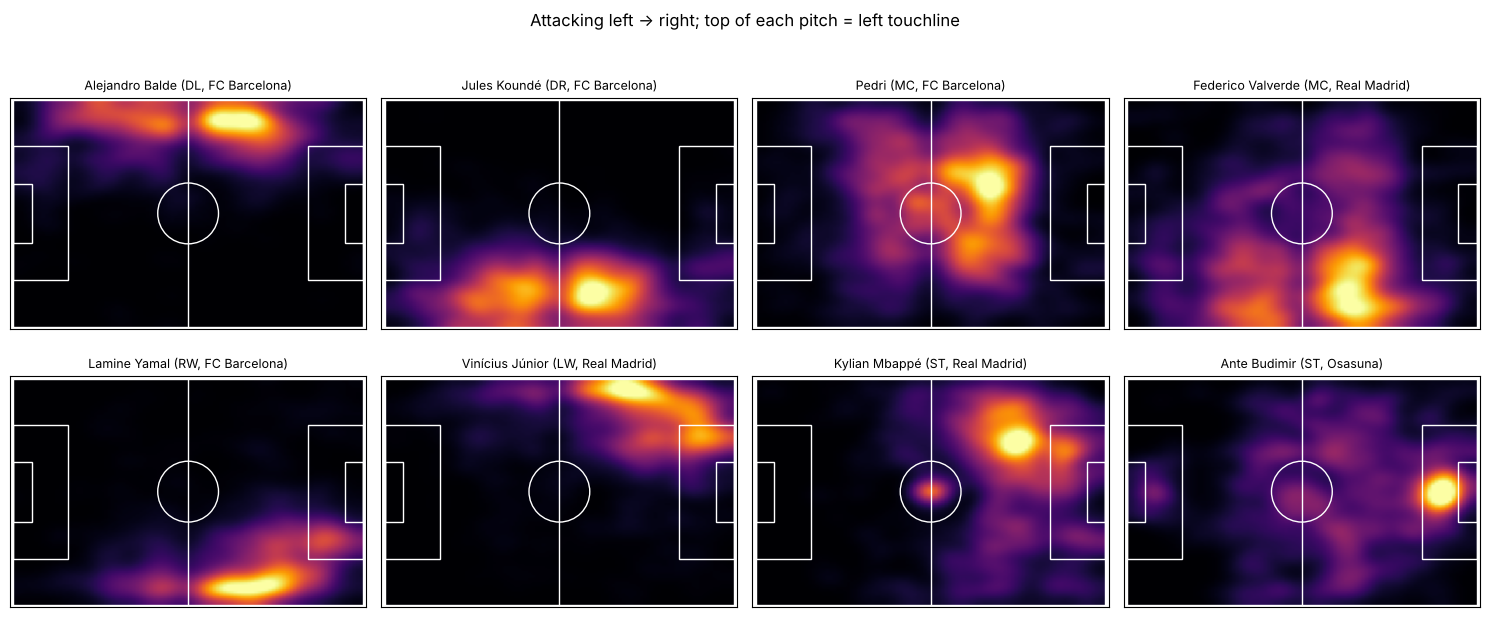

In [16]:
from matplotlib.patches import Rectangle, Ellipse
from scipy.ndimage import gaussian_filter


def draw_pitch(ax):
    """Pitch lines on SofaScore's 0-100 x 0-100 grid (attacking left -> right)."""
    kw = dict(fill=False, lw=1, color="white")
    ax.add_patch(Rectangle((0, 0), 100, 100, **kw))
    ax.plot([50, 50], [0, 100], color="white", lw=1)
    ax.add_patch(Ellipse((50, 50), 17.4, 26.9, **kw))
    for x0 in (0, 100 - 15.7):                               # penalty boxes
        ax.add_patch(Rectangle((x0, 20.4), 15.7, 59.2, **kw))
    for x0 in (0, 100 - 5.2):                                # six-yard boxes
        ax.add_patch(Rectangle((x0, 36.8), 5.2, 26.4, **kw))
    ax.set_xlim(-1, 101); ax.set_ylim(-1, 101); ax.set_xticks([]); ax.set_yticks([])


def player_heatmap(player_name, ax=None, sigma=3.5):
    """SofaScore-style smoothed season heatmap for one player."""
    row = df.loc[df["player_name"] == player_name].iloc[0]
    pts = points.loc[[row["player_id"]]]
    H, _, _ = np.histogram2d(pts["x"], pts["y"], bins=100, range=[[0, 100], [0, 100]], weights=pts["count"])
    H = gaussian_filter(H, sigma)
    ax = ax or plt.gca()
    ax.imshow(H.T, origin="lower", extent=[0, 100, 0, 100], cmap="inferno", aspect=68 / 105,
              vmax=np.quantile(H, 0.995))      # robust colour scale: one hot spot can't wash out the rest
    draw_pitch(ax)
    ax.set_title(f"{player_name} ({row['primary_position_detailed']}, {row['team_name']})", fontsize=9)
    return ax


examples = ["Alejandro Balde", "Jules Koundé", "Pedri", "Federico Valverde",
            "Lamine Yamal", "Vinícius Júnior", "Kylian Mbappé", "Ante Budimir"]
examples = [p for p in examples if p in set(df["player_name"])]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for name, ax in zip(examples, axes.flat):
    player_heatmap(name, ax)
plt.suptitle("Attacking left → right; top of each pitch = left touchline", y=1.0)
plt.tight_layout()

In [17]:
def zone_grid(points, nx=12, ny=8):
    """Your own zone grid from the raw points: returns players x (nx*ny) shares, rows sum to 1.
    Fully vectorised: no per-player Python loop."""
    p = points.reset_index()
    zx = np.minimum(p["x"].astype(int) * nx // 100, nx - 1)
    zy = np.minimum(p["y"].astype(int) * ny // 100, ny - 1)
    grid = (p.assign(zone=[f"z{a:02d}_{b:02d}" for a, b in zip(zx, zy)])
              .pivot_table(index="player_id", columns="zone", values="count", aggfunc="sum", fill_value=0))
    return grid.div(grid.sum(axis=1), axis=0)


grid_12x8 = zone_grid(points, 12, 8)
print(grid_12x8.shape)
grid_12x8.iloc[:3, :8].round(3)

(299, 96)


zone,z00_00,z00_01,z00_02,z00_03,z00_04,z00_05,z00_06,z00_07
player_id,,,,,,,,
17651,0.000,0.000,0.001,0.000,0.001,0.001,0.005,0.002
19356,0.000,0.002,0.000,0.000,0.000,0.000,0.000,0.000
21555,0.007,0.012,0.027,0.002,0.005,0.000,0.000,0.000


## 8. Caveats to keep in mind

- **Season totals scale with minutes.** That's intended: we're describing roles, not per-90 quality. Exercise 6 shows how to check this; compare against the minutes-independent families (`style_*`, heatmap zones).
- **Missing stats.** Progressive passes/carries, pressures, carries into the box and progressive passes received don't exist in SofaScore. The proxies in §6 are stand-ins, not replacements.
- **PAdj** uses each team's **season-average** possession, not match-by-match.
- **Heatmaps** cover LaLiga matches only. They show *where the player was involved*, not where he stood off the ball.
- **Eligibility:** ≥ 900 minutes, no goalkeepers, no mid-season movers (any second club, including abroad). `seasons.csv` records the exact settings this build used.

---
# Part 2: Exercises: cluster the midfielders, step by step

We'll build archetypes for **midfielders** together. Then in Part E you'll repeat it on your own for defenders and attackers.

**How the exercises work**
- Each exercise has a code cell with blanks marked **`___`**. Replace each `___` with your answer, then run the cell (Shift + Enter).
- Right after it there's a **check cell**. Run it: ✅ means you got it, ❌ tells you what to fix.
- Stuck? Every exercise has a 💡 hint. `explain("column_name")` (from section 3) tells you what any column means.
- You can always re-run a cell after fixing it. If things get weird, use `Runtime → Run all` and pick up where you were.

Run the setup cell below first.

In [ ]:
# PART 2 SETUP: run this cell once. You don't need to edit (or understand) it.
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler


import re as _re
import functools as _functools

_BLANK_RE = _re.compile(r"""(?<!['"\w])___(?!['"\w])""")   # a bare ___ (not inside quotes)


class _Blank:
    """Stands in for a blank you haven't filled in yet."""
    def __repr__(self):
        return "___"


___ = _Blank()   # (also stops IPython from using ___ as its 'third-to-last output' shortcut)


def _has_blank(src):
    return bool(_BLANK_RE.search(src or ""))


def _friendly_errors(shell, etype, evalue, tb, tb_offset=None):
    """Plain-English hints for the two most common beginner errors; normal traceback otherwise."""
    cell = shell.user_ns.get("In", [""])[-1]
    if _has_blank(cell):
        print("✏️  This cell still has a ___ blank. Replace every ___ with your answer, then run it again.")
    elif etype is NameError:
        print(f"⚠️  {evalue}\n   (If it's a name from an earlier exercise, run that exercise's cell first.)")
    else:
        shell.showtraceback((etype, evalue, tb), tb_offset=tb_offset)


try:
    get_ipython().set_custom_exc((Exception,), _friendly_errors)
except NameError:
    pass


def _check(fn):
    """Every check: first make sure the exercise cell above was filled in and run."""
    @_functools.wraps(fn)
    def wrapper(*args, **kwargs):
        try:
            history = get_ipython().user_ns.get("In", [])
            if len(history) >= 2 and _has_blank(history[-2]):
                return not_done()
        except NameError:
            pass
        try:
            return fn(*args, **kwargs)
        except Exception as e:
            bad(f"Something in the exercise cell above isn't right yet ({type(e).__name__}: {e}). "
                "Fix it, run it, then run this check again.")
    return wrapper


ok = lambda m: print("✅ " + m)
bad = lambda m: print("❌ " + m)
not_done = lambda: print("✏️  Not finished yet: replace every ___ in the cell above, run it, then run this check again.")
_mid_expected = df[df["role_group"] == "MID"]


@_check
def check_ex1(mids):
    if len(mids) == len(_mid_expected) and set(mids["role_group"]) == {"MID"}:
        ok(f"{len(mids)} midfielders. Nice.")
    else:
        bad('mids should contain only the rows where role_group is "MID" (the text must match exactly, in capitals).')


@_check
def check_ex2(top_npxg):
    want = list(_mid_expected.nlargest(5, "npxg")["player_name"])
    got = list(top_npxg["player_name"])
    if got == want:
        ok("Correct top 5 by npxG.")
    elif len(got) != 5:
        bad(f"Expected 5 rows, got {len(got)}. Check the number inside .head().")
    else:
        bad("Not quite. Did you sort by \"npxg\" with ascending=False (biggest first)?")


@_check
def check_ex3(my_features, X_raw):
    unknown = [f for f in my_features if f not in df.columns]
    if unknown:
        return bad(f"These aren't column names: {unknown}. Check spelling (use explain(...) to look one up).")
    banned = [f for f in my_features if f in ("minutes", "appearances", "starts") or f.startswith("sp_")]
    if banned:
        return bad(f"Leave out {banned}: they measure playing time or set pieces, not playing style.")
    if not 4 <= len(my_features) <= 15:
        return bad("Use somewhere between 4 and 15 features.")
    if X_raw.shape != (len(_mid_expected), len(my_features)):
        return bad("X_raw should have one row per midfielder and one column per feature.")
    ok(f"{X_raw.shape[0]} players x {X_raw.shape[1]} features.")


@_check
def check_ex4(X_raw, X_filled):
    if X_filled.isna().sum().sum() > 0:
        return bad("There are still missing values. Use X_raw.fillna(X_raw.median()).")
    if X_filled.shape != X_raw.shape or not np.allclose(X_filled[X_raw.notna()].fillna(0), X_raw.fillna(0)):
        return bad("Only the missing values should change, nothing else.")
    ok("No missing values left, and the real values are untouched.")


@_check
def check_ex5(X_scaled):
    m, s = X_scaled.mean().abs().max(), X_scaled.std(ddof=0)
    if m < 1e-6 and np.allclose(s, 1):
        ok("Every column now has mean 0 and standard deviation 1.")
    else:
        bad("Columns should have mean ≈ 0 and std ≈ 1. Did you pass X_filled into scaler.fit_transform(...)?")


@_check
def check_ex6(corr_with_minutes, X_raw):
    want = X_raw.corrwith(_mid_expected.set_index("player_name")["minutes"])
    if np.allclose(corr_with_minutes.sort_index(), want.sort_index()):
        ok(f"Most minutes-driven feature: {want.idxmax()} (r = {want.max():.2f}).")
    else:
        bad("Correlate X_raw with the minutes series: X_raw.corrwith(minutes).")


@_check
def check_ex7(labels, X_scaled):
    if len(set(labels)) != 4:
        return bad(f"Expected 4 clusters, found {len(set(labels))}. Check n_clusters.")
    ref = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(X_scaled)
    if adjusted_rand_score(ref, labels) < 0.999:
        return bad("Clusters don't match a fit on X_scaled. Make sure you fit on X_scaled, not X_raw.")
    ok("4 clusters, fitted on the scaled data.")


@_check
def check_ex8(cluster_means, cluster_names):
    if any("___" in str(v) for v in cluster_names.values()):
        return not_done()
    if len(cluster_means) != 4:
        return bad("cluster_means should have one row per cluster (use .groupby(\"cluster\").mean()).")
    ok("Clusters described and named. Do the names match the example players?")


@_check
def check_ex9(inertias, silhouettes):
    if len(inertias) != 9 or len(silhouettes) != 9:
        return bad("Expected 9 values each (k = 2 … 10).")
    if not all(a >= b - 1e-6 for a, b in zip(inertias, inertias[1:])):
        return bad("Inertia should go DOWN as k grows. Are you using km.inertia_?")
    ok(f"Best silhouette at k = {list(range(2, 11))[int(np.argmax(silhouettes))]}. But silhouette isn't everything.")


@_check
def check_ex10(Z_hw_weighted, w_hw):
    if np.allclose(Z_hw_weighted.std(axis=0), np.sqrt(w_hw.values)):
        ok("Each column's spread is now sqrt(weight), so the homework weights carry into the distances.")
    else:
        bad("Multiply the scaled matrix by np.sqrt(w_hw.values).")


@_check
def check_ex11(Z_full, labels6, n_hw):
    stats_part = (Z_full[:, :n_hw].std(axis=0) ** 2).sum()
    if len(set(labels6)) != 6:
        return bad("Expected 6 clusters.")
    if not np.isclose(stats_part, 0.70, atol=0.01):
        return bad(f"The stats block should carry 70% of the weight (it carries {stats_part:.0%}). "
                   "Multiply Z_hw_weighted by np.sqrt(0.70).")
    ok("Weighted stats (70%) + location (30%), 6 clusters.")


@_check
def check_ex12(coords):
    if coords.shape == (len(_mid_expected), 2):
        ok("2-D picture ready.")
    else:
        bad("coords should be (number of midfielders) x 2. Did you fit PCA on Z_full?")


@_check
def check_ex13(most_typical, archetype_names):
    want = set(typical.sort_values("dist").groupby("cluster").head(3).index)
    if set(most_typical.index) != want:
        return bad("Sort by \"dist\" (smallest = most typical) and keep 3 per cluster with .head(3).")
    if any("___" in str(v) for v in archetype_names.values()) or len(archetype_names) != 6:
        return not_done()
    ok("Most typical players found and all 6 clusters named.")


@_check
def check_ex14(best_stat, p90):
    if any(v == "___" for v in best_stat.values()):
        return not_done()
    bad_cols = [v for v in best_stat.values() if v not in p90.columns]
    if bad_cols:
        return bad(f"Not per-90 columns: {bad_cols}. Every option ends in _p90; print(list(p90.columns)) to see them.")
    ok("Ranking stats chosen.")

## Part A: getting comfortable with the table

### Exercise 1: keep only the midfielders
A pandas table (a *DataFrame*) can be filtered by a condition: `df[df["column"] == "value"]` keeps only the rows where the condition is true.

💡 *Hint:* the group names are `"DEF"`, `"MID"`, `"ATT"`. Text values need quotes.

In [ ]:
mids = df[df["role_group"] == ___]
print(len(mids), "midfielders")

In [ ]:
check_ex1(mids)

### Exercise 2: who are the most dangerous midfielders?
Find the 5 midfielders with the highest **npxG** (non-penalty expected goals: how many goals a player's shots were worth, excluding penalties).

💡 *Hint:* `.sort_values("column", ascending=False)` puts the biggest values first, and `.head(n)` keeps the first `n` rows.

In [ ]:
top_npxg = mids.sort_values(___, ascending=___).head(___)
top_npxg[["player_name", "team_name", "npxg", "minutes"]]

In [ ]:
check_ex2(top_npxg)

### Exercise 3: choose the features that describe a midfielder
Clustering groups players who look similar **on the columns you give it**, so this choice matters more than anything else. Pick **6–10** columns that describe *how* a midfielder plays: passing, creating, shooting, winning the ball.

Some ideas: `passes`, `npxg`, `xa`, `padj_tackles`, `padj_interceptions`, `ball_recoveries`, `touches_opp_box`, `take_ons_won`, `long_balls_completed`, `final_third_passes_completed`

💡 *Hint:* a list of column names looks like `["passes", "npxg", "xa"]`. Use `explain("ball_recoveries")` to read about any column. Leave out `minutes` (that's *how much* he played, not *how*).

In [ ]:
my_features = [___, ___, ___, ___, ___, ___]      # e.g. "passes" (with the quotes)

X_raw = mids.set_index("player_name")[my_features]   # one row per player, named by player
X_raw.head()

In [ ]:
check_ex3(my_features, X_raw)

## Part B: getting the numbers ready

### Exercise 4: fill in missing values
Clustering can't handle empty cells. A simple, safe fix is to replace each missing value with that column's **median** (the middle value).

💡 *Hint:* `X_raw.median()` gives the median of every column, and `X_raw.fillna(...)` fills the gaps with it.

In [ ]:
print(X_raw.isna().sum())        # how many missing values per column?

X_filled = X_raw.fillna(___)

In [ ]:
check_ex4(X_raw, X_filled)

### Exercise 5: put every feature on the same scale
K-means measures how *far apart* players are. Right now `passes` is in the thousands and `npxg` is in single digits, so passes would completely drown out shooting. **Standardising** rescales every column to mean 0 and standard deviation 1. After that, a player's value says "how many standard deviations above or below average he is" on that stat.

💡 *Hint:* `scaler.fit_transform(...)` takes the table you want to scale.

In [ ]:
print(X_filled.describe().loc[["mean", "std"]].round(1))   # look how different the scales are

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(___), index=X_filled.index, columns=X_filled.columns)
X_scaled.describe().loc[["mean", "std"]].round(2)

In [ ]:
check_ex5(X_scaled)

### Exercise 6: are we measuring *style* or just *playing time*?
Our stats are **season totals**. A player who played 3,000 minutes racks up more passes than one who played 1,000, even if they play the same role. Let's measure how much each feature just follows minutes played.

A **correlation** near 1 means "goes up together", near 0 means "unrelated".

💡 *Hint:* `.corrwith(other)` correlates every column with another series; here that's `minutes`.

In [ ]:
minutes = mids.set_index("player_name")["minutes"]
corr_with_minutes = X_raw.corrwith(___).sort_values()
corr_with_minutes.round(2)

In [ ]:
check_ex6(corr_with_minutes, X_raw)

✏️ **Think about it** (write 1–2 sentences in the cell below): Which of your features are most tied to minutes? If two players have the same role but one played twice as much, where would k-means put them?

*Your answer:* 

## Part C: your first clustering

### Exercise 7: run k-means
**K-means** in plain words: you choose a number of groups *k*. It drops *k* "centres" among the players, assigns every player to the nearest centre, moves each centre to the middle of its players, and repeats until nothing changes. Players in the same group are similar on your features.

Start with **k = 4**, and fit on the **scaled** data.

💡 *Hint:* `n_clusters` is k. `fit_predict(...)` takes the table to cluster and returns a cluster number (0, 1, 2, …) for every player.

In [ ]:
kmeans = KMeans(n_clusters=___, n_init=10, random_state=0)   # random_state=0 makes the result repeatable
labels = kmeans.fit_predict(___)

mids_clustered = X_raw.copy()
mids_clustered["cluster"] = labels
mids_clustered["cluster"].value_counts().sort_index()    # how many players in each cluster

In [ ]:
check_ex7(labels, X_scaled)

### Exercise 8: what *are* these clusters?
A cluster number means nothing until you look inside. Three steps:
1. the average of each feature per cluster (*what's high, what's low?*)
2. example players per cluster (*do the names make sense to a football fan?*)
3. give each cluster a name

💡 *Hint:* `.groupby("cluster").mean()` averages every column within each cluster.

In [ ]:
cluster_means = mids_clustered.___("cluster").___()
cluster_means.round(2)

In [ ]:
# Example players (the ones with the most minutes come first)
for c in sorted(mids_clustered["cluster"].unique()):
    names = mids_clustered[mids_clustered["cluster"] == c].index[:6]
    print(f"cluster {c}: {', '.join(names)}")

Now name them. Use the homework's midfield archetypes as inspiration: **Anchor, Ball-Winner/Presser, Deep Playmaker, Box-to-Box, Advanced Creator, Goal-Threat Midfielder**. With only 4 clusters, some will be mixes, and that's fine. Write what you see.

In [ ]:
cluster_names = {0: "___", 1: "___", 2: "___", 3: "___"}

In [ ]:
check_ex8(cluster_means, cluster_names)

### Exercise 9: how many clusters should there be?
There's no single right k, but two common guides are:
- **Inertia (elbow plot):** total distance from players to their centre. It always drops as k grows; look for the "elbow" where it stops dropping fast.
- **Silhouette score:** how well separated the clusters are, from −1 to 1, higher is better.

💡 *Hint:* after fitting, the inertia is stored in `km.inertia_`, and `silhouette_score` needs the data and the labels from this k.

In [ ]:
ks = range(2, 11)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    lab = km.fit_predict(X_scaled)
    inertias.append(km.___)
    silhouettes.append(silhouette_score(X_scaled, ___))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(list(ks), inertias, "o-"); ax1.set_title("Elbow: inertia (lower = tighter)"); ax1.set_xlabel("k")
ax2.plot(list(ks), silhouettes, "o-"); ax2.set_title("Silhouette (higher = better separated)"); ax2.set_xlabel("k")
plt.tight_layout()

In [ ]:
check_ex9(inertias, silhouettes)

✏️ **Think about it:** what k would you choose, and why? The homework lists **6** midfield archetypes. Is it OK to pick k for football reasons even if the silhouette score prefers another number?

*Your answer:* 

## Part D: better features: homework weights + where they play

So far every feature counts equally. In our homework we gave each must-have stat a **weight** (progressive passes 11%, npxG 8%, …). Section 6 already built that for you: `homework_matrix(df, "MID")` returns the columns *and* their weights.

### Exercise 10: apply the homework weights
After standardising, multiplying a column by **√weight** makes it count in proportion to its weight. (k-means squares the distances, so the square root ends up as the weight itself.)

💡 *Hint:* the weights are in `w_hw`; use `w_hw.values` to get them as plain numbers.

In [ ]:
X_hw, w_hw = homework_matrix(df, "MID")
X_hw = X_hw.fillna(X_hw.median())
print(w_hw.round(3))                                   # the weights, re-normalised to add up to 1

Z_hw = StandardScaler().fit_transform(X_hw)            # scale first...
Z_hw_weighted = Z_hw * np.sqrt(___)                    # ...then weight

In [ ]:
check_ex10(Z_hw_weighted, w_hw)

### Exercise 11: add *where* they play, and use 6 clusters
Stats say *what* a player does; the heatmap says *where*. We'll add a few location features and give them **30%** of the total weight, leaving **70%** for the stats. Then we use **k = 6**, one per homework archetype.

Note we use `mean_abs_width` (how far from the middle he plays) and **not** `mean_y` (left vs right side). A left-sided and a right-sided midfielder can play exactly the same role!

💡 *Hint:* the stats block gets 70% of the weight, so multiply it by `np.sqrt(0.70)`.

In [ ]:
loc_cols = ["mean_x", "mean_abs_width", "share_def_third", "share_att_third", "share_opp_box"]
loc_cols = [c for c in loc_cols if c not in X_hw.columns]          # don't count a column twice
X_loc = mids.set_index("player_name")[loc_cols]
Z_loc = StandardScaler().fit_transform(X_loc.fillna(X_loc.median()))
Z_loc_weighted = Z_loc * np.sqrt(0.30 / len(loc_cols))             # location: 30%, split over its columns

Z_full = np.hstack([Z_hw_weighted * np.sqrt(___), Z_loc_weighted])  # stats: 70%

km6 = KMeans(n_clusters=___, n_init=10, random_state=0)
labels6 = km6.fit_predict(Z_full)

# How do the new clusters line up with your first try?
pd.crosstab(mids_clustered["cluster"].values, labels6, rownames=["first try (Ex 7)"], colnames=["new (Ex 11)"])

In [ ]:
check_ex11(Z_full, labels6, Z_hw_weighted.shape[1])

### Exercise 12: see the clusters in 2-D
We have many features, so we can't plot them directly. **PCA** squashes them into the 2 directions that keep the most variation, which is good enough to *see* the clusters.

💡 *Hint:* fit PCA on the same matrix you clustered (`Z_full`), and colour the dots by the cluster labels from Exercise 11.

In [ ]:
pca = PCA(n_components=2)
coords = pca.fit_transform(___)
print("share of the variation shown in this picture:", pca.explained_variance_ratio_.sum().round(2))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(coords[:, 0], coords[:, 1], c=___, cmap="tab10", s=30)
for i, name in enumerate(X_hw.index):
    if name in ["Pedri", "Federico Valverde", "Jude Bellingham", "Frenkie de Jong", "Aurélien Tchouaméni", "Dani Olmo"]:
        ax.annotate(name, coords[i], fontsize=8)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Midfielders, coloured by cluster")

In [ ]:
check_ex12(coords)

### Exercise 13: find the most *typical* player of each cluster, and look at their heatmaps
The player closest to a cluster's centre is its best example (its "prototype"). Then we draw the prototype's heatmap with `player_heatmap` from section 7, and use everything we've seen to **name the 6 archetypes**.

💡 *Hint:* smallest distance = most typical, so sort by `"dist"` (smallest first is the default), then keep 3 per cluster.

In [ ]:
dist = np.linalg.norm(Z_full - km6.cluster_centers_[labels6], axis=1)   # distance to own cluster centre
typical = pd.DataFrame({"cluster": labels6, "dist": dist}, index=X_hw.index)

most_typical = typical.sort_values(___).groupby("cluster").head(___)
most_typical.sort_values("cluster")

In [ ]:
# The single most typical player of each cluster, and his season heatmap
top1 = typical.sort_values("dist").groupby("cluster").head(1).sort_values("cluster")
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for (name, row), ax in zip(top1.iterrows(), axes.flat):
    player_heatmap(name, ax)
    ax.set_title(f"cluster {int(row['cluster'])}: {name}", fontsize=9)
plt.tight_layout()

In [ ]:
# What's high / low in each cluster? (average z-score of each homework stat; red = above average)
profile = pd.DataFrame(Z_hw, index=X_hw.index, columns=X_hw.columns).groupby(labels6).mean()
fig, ax = plt.subplots(figsize=(11, 3.5))
im = ax.imshow(profile.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(profile.shape[1]), profile.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(profile)), [f"cluster {i}" for i in profile.index])
plt.colorbar(im, label="avg z-score"); plt.tight_layout()

In [ ]:
archetype_names = {0: "___", 1: "___", 2: "___", 3: "___", 4: "___", 5: "___"}

In [ ]:
check_ex13(most_typical, archetype_names)

### Exercise 14: who's the *best* in each archetype?
Clustering on season totals tells us **what** a player does. To compare **how well** players do it, we switch to **per-90** stats: per 90 minutes, which is fair to players with fewer minutes.

For each archetype, choose one per-90 stat that measures being good at that job. A Goal-Threat Midfielder might use `npxg_p90`; a Ball-Winner might use `padj_tackles_interceptions_p90`.

💡 *Hint:* run `print(list(p90.columns))` to see every option. They all end in `_p90`.

In [ ]:
p90 = load("player_season_per90")
ranked = (typical.reset_index()
          .merge(df[["player_name", "player_id", "minutes"]], on="player_name")
          .merge(p90.drop(columns=["minutes"]), on="player_id"))
ranked["archetype"] = ranked["cluster"].map(archetype_names)
print(list(p90.columns))

In [ ]:
best_stat = {0: "___", 1: "___", 2: "___", 3: "___", 4: "___", 5: "___"}

In [ ]:
check_ex14(best_stat, p90)

In [ ]:
for c, stat in sorted(best_stat.items()):
    top = ranked[ranked["cluster"] == c].nlargest(3, stat)
    print(f"{archetype_names[c]:>24} | top 3 by {stat}: " +
          ", ".join(f"{n} ({v:.2f})" for n, v in zip(top["player_name"], top[stat])))

## Part E: your turn: defenders and attackers

Repeat the recipe on your own. Copy and adapt code from Parts B–D; that's how real data science works!

1. Filter to `"DEF"` (then `"ATT"`).
2. Build the matrix with `homework_matrix(df, "DEF")`, fill missing values, scale, and apply the weights.
3. Add location features, *thinking about which ones matter*. For defenders, the difference between a centre-back and a full-back is width. Is `mean_y` useful now? (Hint: left-back vs right-back is still the same role.)
4. Choose k (the homework lists **5** defender and **6** attacker archetypes), check the elbow/silhouette, and fit.
5. Find each cluster's most typical players, look at their heatmaps, and **name the archetypes**.
6. Rank within each archetype with per-90 stats.

⭐ **Bonus:** wrap steps 2–5 in a function `cluster_group(group, k)` so you can run it for any group in one line.

In [ ]:
# Defenders: your code here

In [ ]:
# Attackers: your code here

## Part F: reflection questions
Write a few sentences for each. There's no single right answer; we'll discuss them together.

1. **Minutes.** Our features are season totals. Use the PCA from Exercise 12: how strongly does the first axis (PC1) correlate with minutes? (`np.corrcoef(coords[:, 0], X_raw.index.map(minutes))`) What does that tell you?
2. **Stability.** Re-run Exercise 11 with `random_state=1` and `random_state=2`. Do the same players end up together? Which clusters are stable, and which move around?
3. **Missing stats.** Progressive carries, pressures and progressive passes received aren't available. Which archetypes are hurt most by that, and which proxy would you trust least?
4. **Borderline players.** Pick a player who sits between two clusters in the PCA plot. Look at his heatmap and stats. Which archetype is he *really*? Can a player have two roles?